In [1]:
## Librerias utilizadas

import pandas as pd  #Para operaciones de Data Frames
import numpy as np  # Operaciones de computación científica
import matplotlib.pyplot as plt  # Librería para gráficos (también utilizada por Pandas)
from IPython.display import Image # Incluir gráficos externos
#import scipy.stats as st # para modelos de asimetría
import os ## Sistema operativo
import math

from scipy import stats

%matplotlib inline

In [2]:
## Carga de datos (archivo .csv)

mainpath = "/Users/vanotole/Documents/Doctorado/Estadistica/Datasets"
filename = "Babyboom.csv"
fullpath = os.path.join(mainpath,filename)

data = pd.read_csv(fullpath, sep='\t')
data  # Mostrar las primeras 10 líneas

,Time,Gender,Weight,Mins
0,5,1,3837,5
1,104,1,3334,64
2,118,2,3554,78
3,155,2,3838,115
4,257,2,3625,177
5,405,1,2208,245
6,407,1,1745,247
7,422,2,2846,262
8,431,2,3166,271
9,708,2,3520,428


1. El set de datos Babyboom.csv incluye un registro de 44 bebés nacidos en un lapso de 24 horas el día 18 de diciembre de 1997 en un hospital en Australia. Se incluyen los datos de hora de nacimiento, género (1=Femenino, 2= Masculino), peso (en gramos) y minutos después de la media noche. De los 44 bebés, 26 de ellos fueron de sexo masculino. Utilizando una distribución binomial, y suponiendo que se trata de un proceso completamente aleatorio (probabilidad de éxito teórica de p=0.5 o demogr ́afica), comparar la probabilidad de observar al menos este número de varones en los 44 nacimientos totales, y concluir si lo observado es algo inusual o no.

In [3]:
### Definimos la ecuación para las combinaciones

def Comb(a,b):
    return (math.factorial(a) / (math.factorial(b)*math.factorial(a-b)))

In [4]:
##
n = 44 ### 44 bebes totales (44 ensayos del experimento binomial)
p = 0.5 ## pro
q = 1-p
x = 26. ## probabilidad exacta de haber observado 26 niños

Prob = Comb(n,x)*(p**x)*(q**(n-x))

print('La probabilidad de tener exactamente 26 niños es =', Prob)

La probabilidad de tener exactamente 26 niños es = 0.05852204463758426


Esta es la probabilidad de haber observado exactamente 26 varones.

In [5]:
# Ajustando los valores de n y p
n = 44
p = 0.5
# definimos una lista de valores r de los 44+1 posibles aciertos 
r_values = list(range(n + 1)) 
# valores pmf de la distribucion binomial 
dist = [stats.binom.pmf(r, n, p) for r in r_values ] 

In [6]:
### De aquí sólo nos interesa la probabilidad de tener mas o igual a x=26

Prob = np.sum(dist[26:])

print('La probabilidad de tener más a igual a 26 niños es =', Prob)

La probabilidad de tener más a igual a 26 niños es = 0.14560761827294758


Con esto podemos concluir que el hecho de que haya pasado esto no es tan raro como parece.


2. Uilizando el data set Babyboom.csv, utilizar el modelo geométrico para modelar el número de nacimientos hasta el punto de nacimiento de un varón. Los tres primeros nacimientos se pueden ignorar puesto que no son nacimientos de varones, de tal forma que se puede utilizar la proporción o probabilidad de éxito estimada de $\hat{p} \sim \frac{26}{41}$ . Comparar en una tabla la probabilidad de tener un varón hasta x intentos, según la distribuci ́on geométrica, y aquella obtenida de los datos observados (dataset). Además, graficar estas dos distribuciones (empírica y teórica).

[16.48780488  6.03212374  2.20687454  0.80739312  0.29538773  0.10806868]


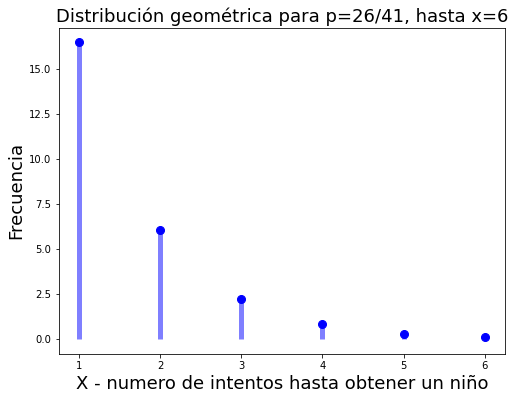

In [7]:

#Primero generamos la distribución teórica, digamos hasta un valor x=6

X = [1, 2, 3, 4, 5, 6] # en la distribucion geómetrica x empieza en 1 y no tiene límite
p = 26/41  # probabilidad teórica de tner un éxito (un varón en este caso)
n = 26 # numero de niños

# Calculate geometric probability distribution
#
geom_pd = n*stats.geom.pmf(X, p) ## esta variable guarda las probabilidades por cada x
# multiplicamos por los 26 niños para obtener una frecuencia de observacion
print(geom_pd)
# Graficar la distribución de probabilidad

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(X, geom_pd, 'bo', ms=8, label='geom pmf')
plt.ylabel("Frecuencia", fontsize="18")
plt.xlabel("X - numero de intentos hasta obtener un niño", fontsize="18")
plt.title("Distribución geométrica para p=26/41, hasta x=6", fontsize="18")
ax.vlines(X, 0, geom_pd, colors='b', lw=5, alpha=0.5)


In [8]:
### Ahora lo calculamos con los datos.


x_obs = [0,0,0,0,0,0] # creamos una lista con 6 entradas = 0 para empezar a contar casos

count = 0 ## ponemos un contador a resetear cada vez que tengamos un caso de varón

for i in range(3,len(data['Gender'])): # empezamos a contar desde el cuarto caso, el anterior sabemos que es varon
    count += 1 ## Aumenta 1 para ver hasta que punto se alcanza otro varón
    
    if data['Gender'][i]==2: ## en el caso que encuentre un varón
        x_obs[count-1] += 1 ## en este caso aumenta la frecuencia para la correspondente intento x 
        #(índice -1 por index python)
        
        count = 0 #reseteamos el contador
        
x_obs  # contiene la frecuencia observada



[18, 3, 3, 0, 1, 0]

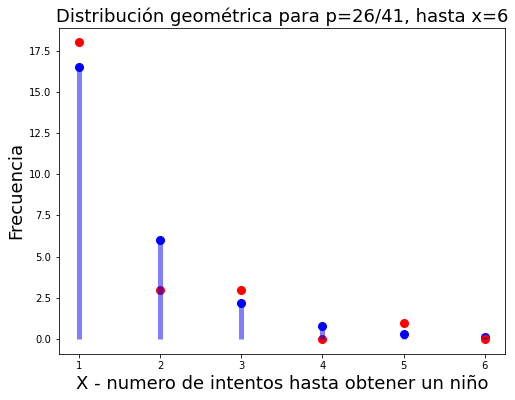

In [9]:
## comparamos gráficamente

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(X, geom_pd, 'bo', ms=8, label='geom pmf')
ax.plot(X, x_obs, 'ro', ms=8, label='geom pmf')


plt.ylabel("Frecuencia", fontsize="18")
plt.xlabel("X - numero de intentos hasta obtener un niño", fontsize="18")
plt.title("Distribución geométrica para p=26/41, hasta x=6", fontsize="18")
ax.vlines(X, 0, geom_pd, colors='b', lw=5, alpha=0.5)

Lo azul es lo esperado y lo rojo es lo observado.

3 Las calificaciones de una clase en particular están distribuidas de manera normal con una media de 80 y un desviaci ́on estándar de 12. 
* Encuentra la calificación x que separa 30 % a la izquierda (menor) y 70 % a la derecha (mayor) de la distribución. 
* Si un estudiante se encuentra en el top 10 % de la clase, al menos cuánto tiene que ser el valor de su calificación?
* ¿Qué rango de calificaciones constituye el 50 % central (a partir de la media) de esta distribución normal?

Se tienen que comparar valores z (unidades=desviaciones estandar) y x(unidades del problema=calificaciones), y para eso se necesitan calcular las probabilidades cumulativas hasta cierto valor $z = \frac{x-\mu}{\sigma}$ 

In [11]:
### Calificación que separa al 30 a la izquierda y 70 a la derecha.
# necesitamos un z con probabilidad CDF = 0.30

mu = 80
sigma = 12

z= stats.norm.ppf(.30) # percent point function, z correspondiente al percentil 30
print('z = ', z)
# cambiamos a unidades de calificacion

x = mu + sigma*z


print('La calificacion que separa al 30 a la izquierda y 70 a la derecha es=',x)
print(z)


z =  -0.5244005127080409
La calificacion que separa al 30 a la izquierda y 70 a la derecha es= 73.7071938475035
-0.5244005127080409


In [13]:
### Si un estudiantes se encuentra en el top 10% de la clase. Calculamos el percentil 90.
## tenemos 90% a la izquierda y 10% a la derecha

mu = 80
sigma = 12

z= stats.norm.ppf(.90) # percent point function, z correspondiente al percentil 90

# cambiamos a unidades de calificacion

x = mu + sigma*z


print('Calificacion que separa al top 10%=',x)



Calificacion que separa al top 10%= 95.3786187865352


In [15]:
### Entre que calificaciones cae el 50% central de la distribucion
### primero nos preguntamos cuales son estos valores z,

### son los percentiles 25 y 75

mu = 80
sigma = 12

z_1 = stats.norm.ppf(.75) # percentil 75
z_2 = stats.norm.ppf(.25) # percentil 25

#entre estos valores cae el 50% de la distribución


# cambiamos a unidades de calificacion

x_1 = mu + sigma*z_1
x_2 = mu + sigma*z_2


print('El 50% central cae entre las calificaciones ',x_2,'y',x_1)



El 50% central cae entre las calificaciones  71.90612299764702 y 88.09387700235298


4 Una caja contiene 24 dulces, de los cuales 12 son pulparindos y 12 son mazapanes. Sea X el número de pulparindos en una muestra de 5 dulces sacados al azar de la caja y sin reemplazo, utilizar una distribución de probabilidad hipergeométrica y valores esperados (de una distribución discreta) para calcular lo siguiente:
* La probabilidad de que exactamente dos de los dulces sean pulparindos. P (X = 2) 
* La probabilidad de que a lo más dos de los dulces sean pulparindos. P (X ≤ 2) 
* La media μ = E(X)
* La varianza σ2 = V ar(X)

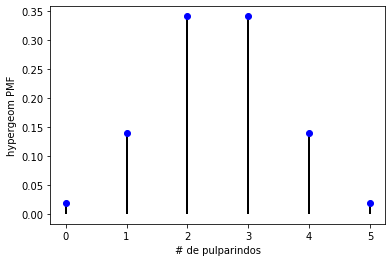

In [30]:
## Graficamos la distribucion completa

N = 24 ## tenemos 24 objetos en Total
b = 12 ## solo 12 de estos son los que nos interesan, pulparindos

n = 5 ## elegimos 5 de estos dulces, no importa cual sea

rv = stats.hypergeom(N, n, b)
x = np.arange(0, n+1)
pmf = rv.pmf(x)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(x, pmf, 'bo')
ax.vlines(x, 0, pmf, lw=2)
ax.set_xlabel('# de pulparindos')
ax.set_ylabel('hypergeom PMF')
plt.show()

Esta sería la distribución completa. Podemos calcular la probabilidad exacta de tener x, $P(X=x)=\frac{_a C_x {_bC_{n-x}}}{{_{a+b}C_n}}$ utilizando lo siguiente: 

In [31]:
### definimos la ecuacion de la distribucion hipergeometrica
## ya se había definido la fórmula de combinacion anteriormente

def Hyp(a,b,x,n):
    return (Comb(a,x)*Comb(b,n-x)/Comb(a+b,n))

# a, numero de objetos de un tipo
# b, numero de objetos del otro tipo
# n, numero de cosas del subconjunto que elegimos
# x, la variable de numero de cosas esperadas de un tipo en las n cosas escogidas

In [32]:
a = 12 ## tenemos 12 pulparindos
b = 12 ## tenemos 12 mazapanes
n = 5 ## elegimos 5 cosas
x = 2 ## nos interesa la probabilidad de observar solo 2 de ellos

print('La prob de observar exactamente 2 pulparindos P(X=2) = ',Hyp(a,b,x,n))

La prob de observar exactamente 2 pulparindos P(X=2) =  0.3416149068322981


Esto de hecho se puede ver en la gráfica para x=2.

In [33]:
### Para calcular que a lo mas dos de esos sean pulparindos P(x <= 2).
## Aqui sumamos las probabilidades para P(x=0) + P(x=1) + P(x=2)

a = 12 ## tenemos 12 pulparindos
b = 12 ## tenemos 12 mazapanes
n = 5 ## elegimos 5 cosas
#La variable x toma varios valores en este problema

print('La prob de observar a lo mas 2 pulparindos P(X<=2) = ',
      Hyp(a,b,0,n)+Hyp(a,b,1,n)+Hyp(a,b,2,n))

La prob de observar a lo mas 2 pulparindos P(X<=2) =  0.5


La media se calcula con $E(X) = \sum xP(X)$, donde $P(X=x)=\frac{_a C_x {_bC_{n-x}}}{{_{a+b}C_n}}$, que ya habiamos definido como función

In [35]:
mu = 0*Hyp(a,b,0,n) + 1*Hyp(a,b,1,n) + 2*Hyp(a,b,2,n) + 3*Hyp(a,b,3,n) + 4*Hyp(a,b,4,n) + 5*Hyp(a,b,5,n)
print('La media o valor esperado del numero de pulparindos es = ',mu)

La media o valor esperado del numero de pulparindos es =  2.4999999999999996


La varianza se puede calcular con $Var(X) =\sum \left[x^2 P(X)\right] - \mu^2 $ 

In [38]:
## Calculo de varianza

var = 0**2. * Hyp(a,b,0,n) + 1**2. * Hyp(a,b,1,n) + 2**2. * Hyp(a,b,2,n) + 3**2. * Hyp(a,b,3,n) + 4**2. * Hyp(a,b,4,n) + 5**2. * Hyp(a,b,5,n) - mu**2.

print('La varianza del numero de pulparindos es = ',var)
print('La desviacion estandar del numero de pulparindos es = ',np.sqrt(var))

La varianza del numero de pulparindos es =  1.0326086956521756
La desviacion estandar del numero de pulparindos es =  1.0161735558713263


5 Suponer que la probabilidad de sufrir de una fiebre a causa de una vacuna contra la influenza es de 0.005. Si se aplica la vacuna a 1000 personas, utilizar la distribución de Poisson para aproximar la probabilidad que:

* Una persona presente fiebre P (x = 1).
* Más de 6 personas presenten fiebre P (x > 6).

Distribucion de poisson $P(X) = \frac{e^{-\lambda} \lambda^x}{x!}$

In [45]:
### definimos la función de la distribución de poisson

def Poisson(l,x):
    return (np.exp(-l)*(l**x)/math.factorial(x))

Si ya sabemos la probabilidad de que la vacuna cause fiebre de 0.005. Para 1000, el promedio de que tengan fiebre por la vacuna es de $1000 \times 0.005 = 5$, es decir $\lambda = 5$.

In [47]:
### La probabilidad de observar exactamente una persona con fiebre
x = 1 #solo una persona
l = 5 #valor lambda

print('La probabilidad de observar solo una persona con fiebre P(x=1) es = ',Poisson(l,x))

La probabilidad de observar solo una persona con fiebre P(x=1) es =  0.03368973499542734


Para la probabilidad de que mas de 6 personas hayan presentado fiebre mejor calculamos el complemento $P(x > 6) = 1 - P(0) + P(1) + P(2) + P(3) + P(4) + P(5) + P(6) = 1 - P(x\le6)$

In [50]:
l = 5  # valor de lambda
# x es variable



Prob = 1 - Poisson(l,0) - Poisson(l,1) - Poisson(l,2) - Poisson(l,3) - Poisson(l,4) - Poisson(l,5) - Poisson(l,6) 

print('La probabilidad de observar mas de 6 personas con fiebre ',Prob)

La probabilidad de observar mas de 6 personas con fiebre  0.23781653702706124


6 Suponer que un examen tiene una calificación media de 75 y una desviación estándar de 10. Asumiendo que la distribución de las calificaciones es aproximadamente normal, responder lo siguiente:

* ¿Cuál es la probabilidad de que una persona escogida al azar saque una calificación de 100 o mayor en este examen?
* ¿Cuál es la calificación que separa al top 2.5 % de las calificaciones?
* En un grupo de 100 personas, ¿cuántas de ellas esperarías que tuvieran una calificación menor a 60?
* Si tomas un grupo de 100 personas y calculas su media (de muestra), ¿Cuál es la probabilidad de esta media de muestra resulte menor a 70? (Tip: Aqu ́ı se usa una distribución muestral de la media aproximadamente normal)



In [ ]:
stats.

In [4]:
#probabilidad de que una persona al azar saque una caliciacion de 100 o mayor en este examen

mu = 75
sigma = 10
x = 100

# primero estandarizamos esta calificacion con un valor z

z = (x - mu)/sigma ## valor z

# Calculamos la pdf de este valor z, la probabilidad por debajo de este valor

pdf = stats.norm.cdf(z) # pdf a este valor z

# pero nos interesa lo que esta a la derecha, mayor a este valor, el complemento

Prob = 1 - pdf

print('La probabilidad de que alguien al azar saque una calificación mayor a 100 P(x>100) = ', Prob)



La probabilidad de que alguien al azar saque una calificación mayor a 100 P(x>100) =  0.006209665325776159


In [8]:
### la calificacion que separa al top 2.5%, se refiere al percentil 97.5%

mu =75
sigma = 10

z = stats.norm.ppf(.975) # percent point function, z correspondiente al percentil 30

print(z)

# cambiamos a unidades de calificacion

x = mu + sigma * z


print('La calificacion que separa al top 2.5% =',x)

1.959963984540054
La calificacion que separa al top 2.5% = 94.59963984540053


In [12]:
### En un grupo de 100 personas ¿cuántas dellas esperarías que tuvieran una calificacion menor a 60?
### menor significa calcular la pdf asociada a este valor

mu =75
sigma = 10
x = 60 # la calificacion que nos interesa
n = 100 # número de alumnos

# Estandarizamos 

z = (x - mu)/sigma ## valor z

print(z)

pdf = stats.norm.cdf(z) # pdf a este valor z, la probabilidad por debajo de este valor

print(pdf)
## Hasta aqui sólo tenemos una probabilidad (sin unidades)
# falta calcular la frecuencia de alumnos, para eso multiplicamos por el total de alumnos

freq = pdf * 100


print('Si tomáramos un grupo de 100 personas, ',freq,'de ellos tendrían calificacion < 60')


-1.5
0.06680720126885807
Si tomáramos un grupo de 100 personas,  6.680720126885807 de ellos tendrían calificacion < 60


Si tomamos una muestra de $n=100$ de estudiantes, esto se comporta como una distribución muestral normal, con $\mu_{\bar{x}} = \mu$ y $\sigma_{\bar{x}} = \frac{\sigma}{\sqrt{n}}$. De tal forma que utilizamos estos valores para calcular el valor z asociado.

In [14]:
# Tomando una muestra de 100 personas, la media calculada se comporta como una distribucióin muestral
## Con los siguientes parámetros

n = 100 #tamaño de la muestra

mu = 75
sigma = 10

mu_x = mu
sigma_x = sigma/np.sqrt(n)

x = 70 # es la media muestral que queremos estadarizar.

# primero estandarizamos esta calificacion con un valor z


z = (x - mu_x)/sigma_x ## valor z

print('z=',z)

# Calculamos la pdf de este valor z, la probabilidad por debajo de este valor

Prob = stats.norm.cdf(z) # pdf a este valor z

# y esta es la probabilidad que nos interesa saber, lo menor a x = 70 media muestral

print('La probabilidad de que la media de una muestra de n=100 personas resulte menor a 70 = ', Prob)

z= -5.0
La probabilidad de que la media de una muestra de n=100 personas resulte menor a 70 =  2.8665157187919333e-07
